In [10]:
# Import packages
from pathlib import Path
import pandas as pd
import seaborn as sns

In [5]:
# Import cleaned 2000+ csv's and create file paths
root_fldr = Path.cwd().parent
raw_fldr = root_fldr / "data" / "raw"
processed_fldr = root_fldr / "data" / "processed"

#Create raw csv file variables
fire25_csv = processed_fldr / "fire25_2000.csv"
rxburn25_csv = processed_fldr / "rxburn25_2000.csv"

#Import csv as data frames
fire25 = pd.read_csv(fire25_csv)
rxburn25 = pd.read_csv(rxburn25_csv)

In [6]:
# Show all unique values in the 'CAUSE' column of the fire25 data frame
fire25['CAUSE'].unique()

<StringArray>
[  'Unknown / Unidentified',                'Lightning',
                   'Debris',         'Electrical Power',
            'Miscellaneous',                  'Vehicle',
            'Equipment Use',                    'Arson',
                 'Campfire',        'Playing with Fire',
                'Structure',                 'Railroad',
 'Non-Firefighter Training',  'Escaped Prescribed Burn',
                  'Smoking',                 'Aircraft',
   'Illegal Alien Campfire',     'Firefighter Training']
Length: 18, dtype: str

In [24]:
# Show the count of each unique value in the 'CAUSE' column of the fire25 data frame and make it into a new data frame
fire_cause_counts = fire25['CAUSE'].value_counts().reset_index()

In [27]:
fire_cause_counts

,CAUSE,count
0,Unknown / Unidentified,2651
1,Lightning,1832
2,Equipment Use,991
3,Miscellaneous,939
4,Vehicle,588
5,Arson,526
6,Electrical Power,419
7,Debris,370
8,Campfire,222
9,Playing with Fire,99


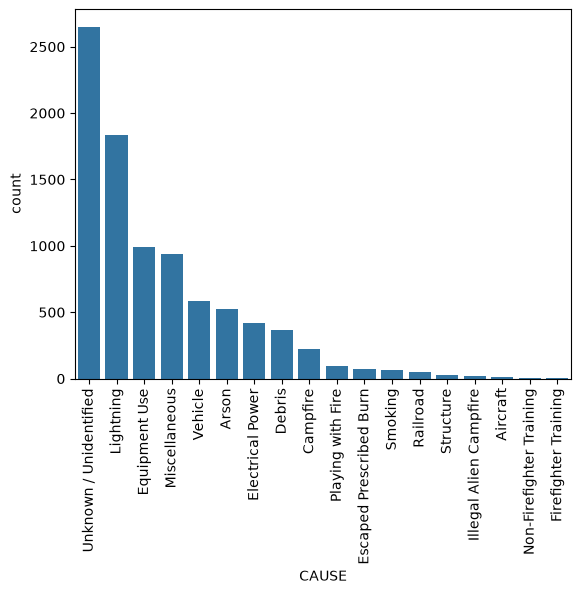

In [ ]:
# Histogram/barplot of fire25['CAUSE'] counts using seaborn and sort descending by count
sns.barplot(
            data=fire_cause_counts, 
             x='CAUSE',
             y='count', 
             ).tick_params(axis='x', labelrotation=90)

In [42]:
# Cause summary data frame/table
cause_summary = (fire25.groupby(['CAUSE'])
                 .agg(
                     count=('CAUSE', 'count'),
                     mean_area_burned=('GIS_ACRES', 'mean'),
                     total_area_burned=('GIS_ACRES', 'sum'),
                 )
                 .sort_values(by='mean_area_burned', ascending=False)
)

In [32]:
# Display Cuase summary data frame/table
cause_summary

,count,mean_area_burned,total_area_burned
CAUSE,,,
Aircraft,14,2452.859504,3.434003e+04
Arson,526,2712.388250,1.426716e+06
Campfire,222,4042.850023,8.975127e+05
Debris,370,929.819408,3.440332e+05
Electrical Power,419,3566.822625,1.494499e+06
Equipment Use,991,1245.485617,1.234276e+06
Escaped Prescribed Burn,71,578.017092,4.103921e+04
Firefighter Training,2,1082.385803,2.164772e+03
Illegal Alien Campfire,17,83.463737,1.418884e+03


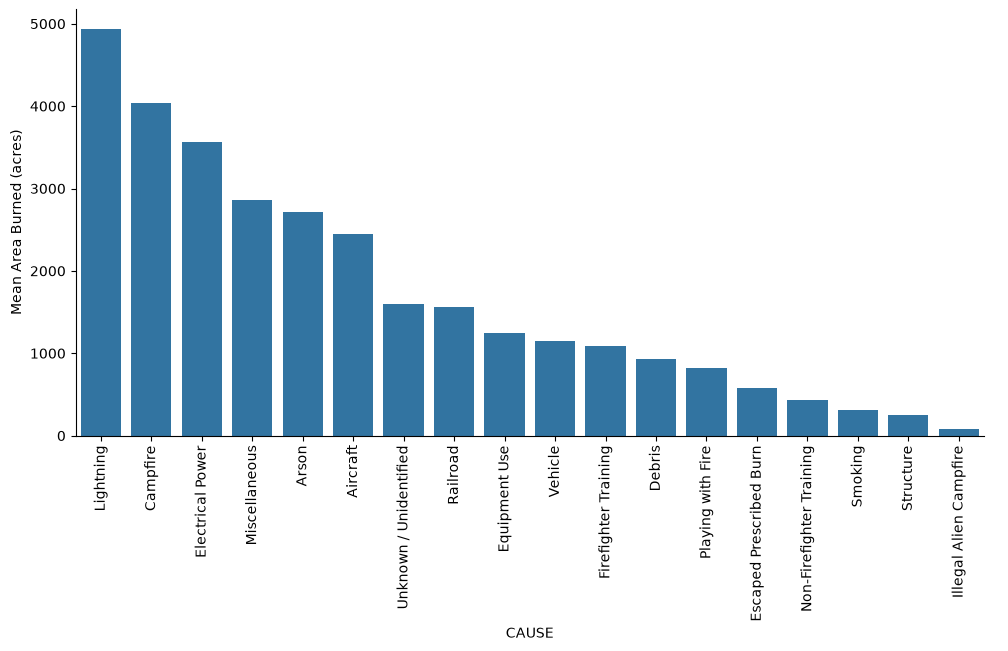

In [52]:
# Plot mean area burned by cause
g = sns.catplot(
            data=cause_summary,
            x='CAUSE',
            y='mean_area_burned',
            kind='bar',
            aspect=2
            ).tick_params(axis='x', labelrotation=90)

g.set(
    ylabel='Mean Area Burned (acres)'
)

In [ ]:
# Create year summary data frame/table
year_summary = (fire25.groupby(['YEAR'])
                 .agg(
                     count=('YEAR', 'count'),
                     mean_area_burned=('GIS_ACRES', 'mean'),
                     total_area_burned=('GIS_ACRES', 'sum'),
                 )
                 .sort_values(by='mean_area_burned', ascending=False)
)

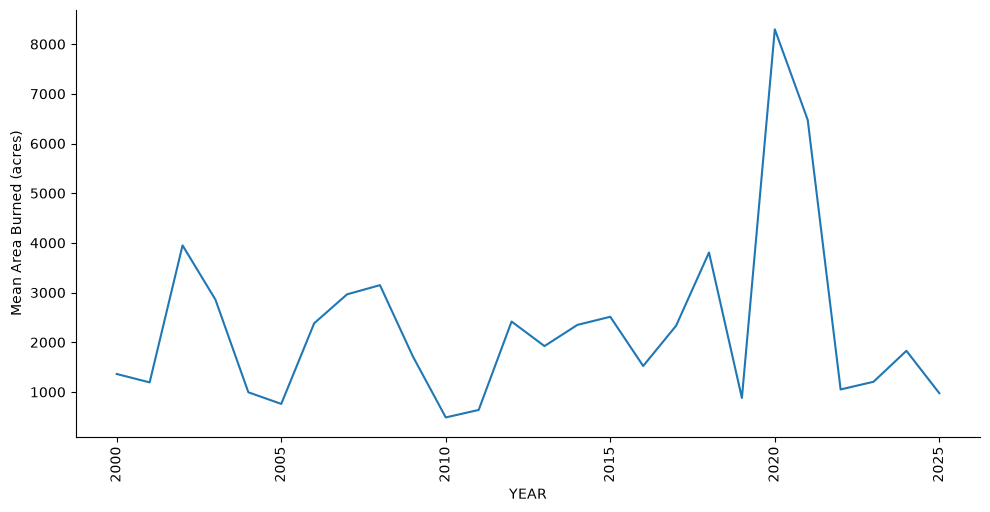

In [53]:
# Plot mean area burned by year
g = sns.relplot(
            data=year_summary,
            x='YEAR',
            y='mean_area_burned',
            kind='line',
            aspect=2
            ).tick_params(axis='x', labelrotation=90)

g.set(
    ylabel="Mean Area Burned (acres)"
)